# 03 · Deep learning on tabular data (Unit 3)

Two neural approaches built for tables, on exactly the same time-based splits as notebook 02:
* **TabNet** (`pytorch-tabnet`): sequential attention picks a sparse set of features at each decision step.
* **fastai tabular learner**: entity embeddings for categoricals + an MLP with batch-norm and dropout.

Neural nets need what trees don't: **missing values filled** (plus indicator columns), **inputs normalised**,
**categorical embeddings**, and **regularisation** (dropout, weight decay, early stopping). All
preprocessing is fit on the training years only. Then an honest comparison with XGBoost.

In [1]:
import json
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from pytorch_tabnet.tab_model import TabNetClassifier, TabNetRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

from src import features as F
from src.evaluate import clf_metrics, reg_metrics, youden_threshold
from src.train import _params, fit_xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = Path("docs/figures"); OUT = Path("frontend/public/insights")
SEED = 42

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

torch.set_num_threads(4)
df = F.load()
tr, va, te = F.splits(df)
trva = pd.concat([tr, va])
NUM, CAT = F.numeric_names(), list(F.CATEGORICAL)
print(f"train {len(tr)} | val {len(va)} | test {len(te)} | numeric {len(NUM)} | categorical {CAT}")

train 256 | val 58 | test 290 | numeric 33 | categorical ['exchange', 'sector']


## 1. Preprocessing for neural nets
* numeric: median imputation **with missing-indicator columns** (so "missing" stays visible), then standard scaling
* categorical: integer codes → learned embeddings inside the network
* target: raw listing gain %, Huber loss (δ = 10) so a few 100 %+ listings don't dominate

In [2]:
class TabPrep:
    def fit(self, X):
        self.imp = SimpleImputer(strategy="median", add_indicator=True).fit(X[NUM])
        self.sc = StandardScaler().fit(self.imp.transform(X[NUM]))
        return self

    def transform(self, X):
        num = self.sc.transform(self.imp.transform(X[NUM]))
        cats = np.stack([X[c].cat.codes.values for c in CAT], axis=1)
        return np.hstack([cats, num]).astype(np.float32)

cat_idxs = list(range(len(CAT)))
cat_dims = [len(F.CATEGORIES[c]) for c in CAT]

## 2. TabNet


Early stopping occurred at epoch 64 with best_epoch = 24 and best_val_0_mae = 15.27748
TabNet stopped at epoch 25 in 18.4s -> {'MAE': 15.277, 'RMSE': 23.427, 'R2': 0.448}


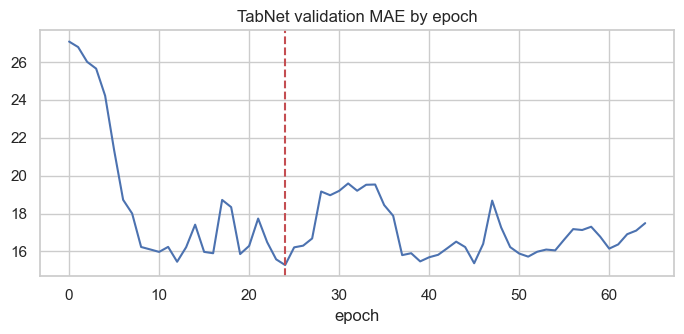

In [3]:
TABNET = dict(n_d=8, n_a=8, n_steps=3, gamma=1.5, lambda_sparse=1e-3, cat_idxs=cat_idxs, cat_dims=cat_dims, cat_emb_dim=[2, 4],
              optimizer_params=dict(lr=2e-2, weight_decay=1e-4), mask_type="entmax", verbose=0, seed=SEED)

def fit_tabnet(Xa, ya, Xb=None, yb=None, kind="reg", max_epochs=300, patience=40):
    seed_all()
    m = (TabNetRegressor if kind == "reg" else TabNetClassifier)(**TABNET)
    kw = dict(max_epochs=max_epochs, batch_size=64, virtual_batch_size=32, drop_last=False)
    if kind == "reg":
        kw["loss_fn"] = torch.nn.HuberLoss(delta=10.0)
        ya = ya.reshape(-1, 1); yb = None if yb is None else yb.reshape(-1, 1)
    if Xb is not None:
        m.fit(Xa, ya, eval_set=[(Xb, yb)], eval_metric=["mae"] if kind == "reg" else ["auc"], patience=patience, **kw)
    else:
        m.fit(Xa, ya, patience=0, **kw)
    return m

prep = TabPrep().fit(F.engineer(tr))
A, B, C = (prep.transform(F.engineer(d)) for d in (tr, va, te))
ya, yb = tr.listing_gain_pct.values, va.listing_gain_pct.values

t0 = time.time()
tn = fit_tabnet(A, ya, B, yb, "reg")
tn_time = time.time() - t0
tn_epochs = tn.best_epoch + 1
tn_val = tn.predict(B).ravel()
print(f"TabNet stopped at epoch {tn_epochs} in {tn_time:.1f}s ->", {k: round(v, 3) for k, v in reg_metrics(yb, tn_val).items()})

plt.figure(figsize=(7, 3.5)); plt.plot(tn.history["val_0_mae"]); plt.axvline(tn.best_epoch, ls="--", c="r")
plt.title("TabNet validation MAE by epoch"); plt.xlabel("epoch"); plt.tight_layout(); plt.savefig(FIG / "dl_tabnet_curve.png", dpi=120); plt.show()

In [4]:
tnc = fit_tabnet(A, tr.listed_positive.astype(int).values, B, va.listed_positive.astype(int).values, "clf")
tnc_epochs = tnc.best_epoch + 1
tnc_val = tnc.predict_proba(B)[:, 1]
print("TabNet classifier val:", {k: round(v, 3) for k, v in clf_metrics(va.listed_positive, tnc_val).items()})


Early stopping occurred at epoch 55 with best_epoch = 15 and best_val_0_auc = 0.85687
TabNet classifier val: {'ROC_AUC': 0.857, 'F1': 0.891, 'Precision': 0.833, 'Recall': 0.957, 'Accuracy': 0.81, 'Balanced_Accuracy': 0.57}


TabNet's attention masks give a built-in global feature importance:

In [5]:
names = CAT + list(prep.imp.get_feature_names_out(NUM))
imp_tn = pd.Series(tn.feature_importances_, index=names).sort_values(ascending=False)
imp_tn.head(12).round(3)

log_total_x                             0.407
log_nii_x                               0.143
log_qib_x                               0.142
anchor_pct_of_issue                     0.100
issue_days_open                         0.027
log_revenue_cr                          0.022
log_retail_x                            0.016
missingindicator_log_employee_x         0.015
retail_reserved_pct                     0.013
prev_gain_mean_90d                      0.012
missingindicator_anchor_pct_of_issue    0.012
revenue_growth_pct                      0.010
dtype: float64

## 3. fastai tabular learner

In [6]:
from fastai.tabular.all import (
    Categorify, CategoryBlock, FillMissing, Normalize, RegressionBlock, TabularPandas,
    accuracy, mae, set_seed, tabular_config, tabular_learner,
)

def fai_frame(d):
    X = F.engineer(d).copy()
    X["y_reg"] = d["listing_gain_pct"].values
    X["y_clf"] = d["listed_positive"].astype(int).astype(str).values
    return X.reset_index(drop=True)

def fit_fastai(train_df, valid_df, kind="reg", epochs=40, lr=3e-3):
    set_seed(SEED, reproducible=True)
    # FillMissing only learns a fill value for columns that have NaN in the training rows; a column
    # complete in training (e.g. QIB in an early CV fold) would crash on later NaN, so fill those with the training median
    # columns entirely missing in the training rows (bNII/sNII, P/E, margins in the early CV folds) carry no
    # information for this fit; set them to a constant 0 everywhere, or Normalize divides later values by a zero std
    all_nan = [c for c in NUM if train_df[c].isna().all()]
    train_df = train_df.assign(**{c: 0.0 for c in all_nan})
    valid_df = valid_df.assign(**{c: 0.0 for c in all_nan})
    no_nan = [c for c in NUM if train_df[c].notna().all()]
    fill = train_df[no_nan].median()
    valid_df = valid_df.fillna(fill)
    both = pd.concat([train_df, valid_df]).reset_index(drop=True)
    splits = (list(range(len(train_df))), list(range(len(train_df), len(both))))
    to = TabularPandas(both, procs=[Categorify, FillMissing, Normalize], cat_names=list(CAT), cont_names=list(NUM),  # copies: FillMissing appends _na columns in place
                       y_names="y_reg" if kind == "reg" else "y_clf",
                       y_block=RegressionBlock() if kind == "reg" else CategoryBlock(), splits=splits)
    dls = to.dataloaders(bs=64, num_workers=0)
    cfg = tabular_config(ps=[0.3, 0.2], embed_p=0.1, use_bn=True)
    learn = tabular_learner(dls, layers=[128, 64], config=cfg, wd=0.1,
                            loss_func=torch.nn.HuberLoss(delta=10.0) if kind == "reg" else None,
                            metrics=mae if kind == "reg" else accuracy)
    with learn.no_bar(), learn.no_logging():
        learn.fit_one_cycle(epochs, lr)
    learn.fill_values, learn.zero_cols = fill, all_nan
    return learn, to

def fai_predict(learn, d, kind="reg"):
    dl = learn.dls.test_dl(fai_frame(d).assign(**{c: 0.0 for c in learn.zero_cols}).fillna(learn.fill_values))
    p, _ = learn.get_preds(dl=dl)
    assert torch.isfinite(p).all(), "fastai produced non-finite predictions"
    return p.numpy().ravel() if kind == "reg" else p.numpy()[:, 1]

# pick the number of epochs on validation (fastai has no early stopping by default; we scan)
scan = []
for ep in (10, 20, 40, 80):
    learn, _ = fit_fastai(fai_frame(tr), fai_frame(va), "reg", epochs=ep)
    scan.append({"epochs": ep, **reg_metrics(yb, fai_predict(learn, va))})
scan = pd.DataFrame(scan).round(3); print(scan)
fai_epochs = int(scan.sort_values("MAE").iloc[0]["epochs"])

t0 = time.time()
fai, _ = fit_fastai(fai_frame(tr), fai_frame(va), "reg", epochs=fai_epochs)
fai_time = time.time() - t0
fai_val = fai_predict(fai, va)
faic, _ = fit_fastai(fai_frame(tr), fai_frame(va), "clf", epochs=fai_epochs)
faic_val = fai_predict(faic, va, "clf")
print("fastai reg val:", {k: round(v, 3) for k, v in reg_metrics(yb, fai_val).items()})
print("fastai clf val:", {k: round(v, 3) for k, v in clf_metrics(va.listed_positive, faic_val).items()})

   epochs     MAE    RMSE     R2
0      10  26.405  38.330 -0.477
1      20  25.263  35.981 -0.302
2      40  24.259  34.204 -0.176
3      80  20.597  30.982  0.035


fastai reg val: {'MAE': 20.597, 'RMSE': 30.982, 'R2': 0.035}
fastai clf val: {'ROC_AUC': 0.677, 'F1': 0.795, 'Precision': 0.854, 'Recall': 0.745, 'Accuracy': 0.69, 'Balanced_Accuracy': 0.6}


## 4. Cross-validation on the training years (TimeSeriesSplit, 5 folds)
One validation year is a single draw. CV over 2012–2022 shows how stable each model is.

In [7]:
rp, cp = _params()
tscv = TimeSeriesSplit(n_splits=5)
cv_rows = []
for fold, (i_tr, i_va) in enumerate(tscv.split(tr)):
    a, b = tr.iloc[i_tr], tr.iloc[i_va]
    pa = TabPrep().fit(F.engineer(a))
    m = fit_tabnet(pa.transform(F.engineer(a)), a.listing_gain_pct.values, max_epochs=tn_epochs, kind="reg")
    cv_rows.append({"fold": fold, "model": "TabNet", "MAE": reg_metrics(b.listing_gain_pct, m.predict(pa.transform(F.engineer(b))).ravel())["MAE"]})
    l, _ = fit_fastai(fai_frame(a), fai_frame(b), "reg", epochs=fai_epochs)
    cv_rows.append({"fold": fold, "model": "fastai MLP", "MAE": reg_metrics(b.listing_gain_pct, fai_predict(l, b))["MAE"]})
    x = fit_xgb(rp, F.engineer(a), a.listing_gain_pct, n_estimators=300, kind="reg")
    cv_rows.append({"fold": fold, "model": "XGBoost", "MAE": reg_metrics(b.listing_gain_pct, x.predict(F.engineer(b)))["MAE"]})
    cv_rows.append({"fold": fold, "model": "Baseline: median", "MAE": reg_metrics(b.listing_gain_pct, np.full(len(b), a.listing_gain_pct.median()))["MAE"]})
cv = pd.DataFrame(cv_rows)
cv_summary = cv.groupby("model")["MAE"].agg(["mean", "std"]).round(2).sort_values("mean")
cv_summary

,mean,std
model,,
XGBoost,15.88,6.67
TabNet,18.05,5.07
fastai MLP,20.87,7.44
Baseline: median,24.66,10.86


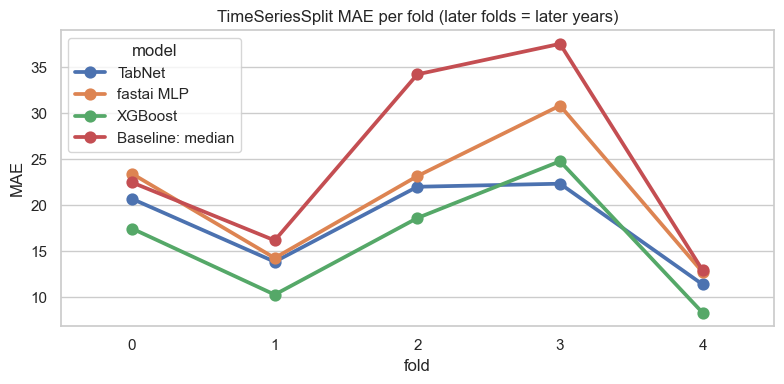

In [8]:
plt.figure(figsize=(8, 4)); sns.pointplot(data=cv, x="fold", y="MAE", hue="model"); plt.title("TimeSeriesSplit MAE per fold (later folds = later years)")
plt.tight_layout(); plt.savefig(FIG / "dl_cv_folds.png", dpi=120); plt.show()

## 5. Honest comparison on validation (2023) and test (2024+)
For test, every model is refit on 2012–2023 with the epochs / trees chosen on validation.

In [9]:
Xtr_, Xva_, Xte_ = F.engineer(tr), F.engineer(va), F.engineer(te)
xgr = fit_xgb(rp, Xtr_, tr.listing_gain_pct, Xva_, va.listing_gain_pct, kind="reg")
xgc = fit_xgb(cp, Xtr_, tr.listed_positive.astype(int), Xva_, va.listed_positive.astype(int), kind="clf")
xg_val, xgc_val = xgr.predict(Xva_), xgc.predict_proba(Xva_)[:, 1]

# refits on train+val
prep2 = TabPrep().fit(F.engineer(trva))
A2, C2 = prep2.transform(F.engineer(trva)), prep2.transform(Xte_)
tn_te = fit_tabnet(A2, trva.listing_gain_pct.values, max_epochs=tn_epochs, kind="reg").predict(C2).ravel()
tnc_te = fit_tabnet(A2, trva.listed_positive.astype(int).values, max_epochs=tnc_epochs, kind="clf").predict_proba(C2)[:, 1]
fai2, _ = fit_fastai(fai_frame(trva), fai_frame(te.iloc[:5]), "reg", epochs=fai_epochs)   # valid split unused for training
fai_te = fai_predict(fai2, te)
faic2, _ = fit_fastai(fai_frame(trva), fai_frame(te.iloc[:5]), "clf", epochs=fai_epochs)
faic_te = fai_predict(faic2, te, "clf")
Xtv = F.engineer(trva)
xg_te = fit_xgb(rp, Xtv, trva.listing_gain_pct, n_estimators=xgr.best_iteration + 1, kind="reg").predict(Xte_)
xgc_te = fit_xgb(cp, Xtv, trva.listed_positive.astype(int), n_estimators=xgc.best_iteration + 1, kind="clf").predict_proba(Xte_)[:, 1]

yte, cte, cva = te.listing_gain_pct.values, te.listed_positive.astype(int).values, va.listed_positive.astype(int).values
med = trva.listing_gain_pct.median()
rows = []
for name, pv, pt, cv_, ct in [
    ("Baseline: median", np.full(len(va), tr.listing_gain_pct.median()), np.full(len(te), med), None, None),
    ("XGBoost", xg_val, xg_te, xgc_val, xgc_te),
    ("TabNet", tn_val, tn_te, tnc_val, tnc_te),
    ("fastai MLP", fai_val, fai_te, faic_val, faic_te),
]:
    r = {"model": name}
    r.update({f"val_{k}": v for k, v in reg_metrics(yb, pv).items()})
    r.update({f"test_{k}": v for k, v in reg_metrics(yte, pt).items()})
    if cv_ is not None:
        r["val_ROC_AUC"] = clf_metrics(cva, cv_)["ROC_AUC"]; r["test_ROC_AUC"] = clf_metrics(cte, ct)["ROC_AUC"]
        # up/down cut-off chosen on validation for each model (scores are on different scales)
        cm = clf_metrics(cte, ct, youden_threshold(cva, cv_))
        r["test_F1"], r["test_Balanced_Accuracy"] = cm["F1"], cm["Balanced_Accuracy"]
    rows.append(r)
comparison = pd.DataFrame(rows).round(3)
comparison

,model,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2,val_ROC_AUC,test_ROC_AUC,test_F1,test_Balanced_Accuracy
0,Baseline: median,25.664,38.493,-0.490,18.619,30.059,-0.112,NaN,NaN,NaN,NaN
1,XGBoost,14.812,22.662,0.484,20.099,27.797,0.049,0.820,0.823,0.784,0.746
2,TabNet,15.277,23.427,0.448,18.642,25.276,0.214,0.857,0.767,0.789,0.670
3,fastai MLP,20.597,30.982,0.035,16.218,24.117,0.284,0.677,0.800,0.808,0.731


## 6. Why trees vs nets comes out this way

* **On the data used to choose models, the trees win.** XGBoost has the lowest TimeSeriesSplit CV MAE (15.9 ± 6.7) and the lowest 2023 validation MAE (14.8). TabNet is close on 2023 (15.3) but worse in CV (18.1). fastai is far behind on both (CV 20.9, 2023 20.6); it needed 80 epochs just to get clearly below the median baseline.
* **256 training rows is very little for a neural net.** Trees take skewed, partly missing, mixed-type columns as they are. The nets need imputation, missing-indicator columns, scaling and embeddings first, and still overfit quickly (TabNet's best epoch was 25 of 64 before early stopping).
* **The test years reverse the ranking:** fastai 16.2, TabNet 18.6, XGBoost 20.1 test MAE, against 18.6 for the median baseline. We do **not** switch models because of this: picking the model by its test score would make the test score meaningless. The reason is visible in the errors: all models over-predict on 2024+ (mean bias XGBoost +12.1, TabNet +9.5, fastai +5.4 points). Median subscription jumped from about 9x in the training years to about 34x in 2023 onward, without listing gains rising to match, so a model that learned "34x means a hot IPO" overshoots. XGBoost fits the old relationship most closely and overshoots most; the over-regularised fastai net is pulled toward the average and suffers least.
* **Up/down:** with each model's cut-off chosen on 2023, XGBoost has the best test ROC-AUC (0.82) and balanced accuracy (0.75); TabNet 0.77 / 0.67, fastai 0.80 / 0.73.
* **Cost and explainability:** TabNet trained in about 18 s and fastai in about 7 s, against under a second for XGBoost. TabNet's attention importance agrees with SHAP in notebook 04 that total subscription dominates, but it gives no per-IPO additive explanation, which the web app needs.

**Decision:** XGBoost stays the production model; the deep models are offered to a validation-weighted blend in notebook 04.

## 7. Save predictions for the blend

In [10]:
# predictions saved for the blend in notebook 04
preds = pd.concat([
    pd.DataFrame({"ipo_id": va.ipo_id.values, "split": "val", "xgb": xg_val, "tabnet": tn_val, "fastai": fai_val,
                  "xgb_p": xgc_val, "tabnet_p": tnc_val, "fastai_p": faic_val}),
    pd.DataFrame({"ipo_id": te.ipo_id.values, "split": "test", "xgb": xg_te, "tabnet": tn_te, "fastai": fai_te,
                  "xgb_p": xgc_te, "tabnet_p": tnc_te, "fastai_p": faic_te}),
])
Path("data/interim").mkdir(parents=True, exist_ok=True)
preds.to_csv("data/interim/model_predictions.csv", index=False)

export = {"cv": cv_summary.reset_index().to_dict(orient="records"), "comparison": comparison.to_dict(orient="records"),
          "epochs": {"tabnet": int(tn_epochs), "fastai": int(fai_epochs)}, "train_seconds": {"tabnet": tn_time, "fastai": fai_time},
          "tabnet_importance": [{"feature": k, "importance": float(v)} for k, v in imp_tn.head(12).items()]}
(OUT / "deep.json").write_text(json.dumps(export, default=float))
print("wrote predictions and", OUT / "deep.json")

wrote predictions and frontend\public\insights\deep.json
